In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

dateien = sorted(Path("data/linie").glob("*_linie_48.csv"))
alle = pd.concat([pd.read_csv(p, dtype=str) for p in dateien], ignore_index=True)

alle["tag"] = pd.to_datetime(alle["BETRIEBSTAG"], format="%d.%m.%Y")
# Planzeit: normalerweise die Abfahrt, an der Endhaltestelle gibt es nur eine Ankunft
alle["planzeit"] = pd.to_datetime(
    alle["ABFAHRTSZEIT"].fillna(alle["ANKUNFTSZEIT"]), format="mixed", dayfirst=True
)
# Eine Fahrt eindeutig machen: dieselbe Fahrtnummer gibt es an jedem Tag
alle["fahrt"] = alle["BETRIEBSTAG"] + "_" + alle["FAHRT_BEZEICHNER"]

print("Tage:", alle["tag"].nunique(), "· Zeilen:", len(alle), "· Fahrten:", alle["fahrt"].nunique())

Tage: 92 · Zeilen: 201061 · Fahrten: 13885


In [2]:
# Halte jeder Fahrt in zeitlicher Reihenfolge, der letzte Halt ist das Ziel
alle = alle.sort_values(["fahrt", "planzeit"])
endstation = alle.groupby("fahrt")["HALTESTELLEN_NAME"].last()
alle["ziel"] = alle["fahrt"].map(endstation)

STADT_ZIELE = ["Bahnhof SBB", "Bahnhof St.Johann"]
alle["richtung"] = alle["ziel"].apply(
    lambda z: "stadteinwärts" if z in STADT_ZIELE else "stadtauswärts"
)

print(alle.groupby("richtung")["ziel"].value_counts())

richtung       ziel             
stadtauswärts  Basel Bachgraben     71971
stadteinwärts  Bahnhof SBB          97938
               Bahnhof St.Johann    31152
Name: count, dtype: int64


In [3]:
gemessen = alle[alle["AB_PROGNOSE_STATUS"] == "REAL"].copy()
gemessen["ist"] = pd.to_datetime(gemessen["AB_PROGNOSE"], format="mixed", dayfirst=True)
gemessen["verspaetung_min"] = (gemessen["ist"] - gemessen["planzeit"]).dt.total_seconds() / 60

# Messfehler weglassen: mehr als 2 Min. zu früh oder über 30 Min. zu spät
gemessen = gemessen[gemessen["verspaetung_min"].between(-2, 30)]

gemessen["stunde"] = gemessen["planzeit"].dt.hour
gemessen["wochentag"] = gemessen["tag"].dt.weekday          # 0 = Montag
gemessen["wochenende"] = gemessen["wochentag"] >= 5

print("Gemessene Abfahrten:", len(gemessen))

Gemessene Abfahrten: 183541


C:\Users\stajinjose.chirakal\AppData\Local\Temp\ipykernel_12916\763491172.py:9: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  gemessen["wochentag"] = gemessen["tag"].dt.weekday          # 0 = Montag


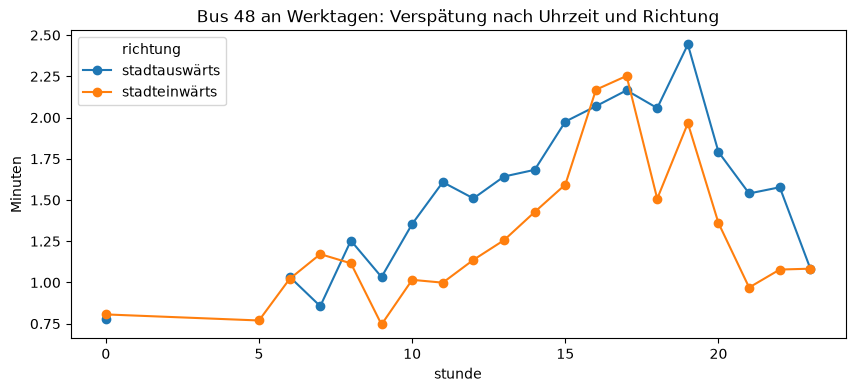

In [4]:
werktage = gemessen[~gemessen["wochenende"]]
werktage.pivot_table(
    index="stunde", columns="richtung", values="verspaetung_min", aggfunc="mean"
).plot(marker="o", figsize=(10, 4), title="Bus 48 an Werktagen: Verspätung nach Uhrzeit und Richtung")
plt.ylabel("Minuten")
plt.show()

In [5]:
WETTER_URL = "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn/bas/ogd-smn_bas_h_recent.csv"
CODES = {
    "tre200h0": "temp",       # Lufttemperatur, Stundenmittel (°C)
    "rre150h0": "regen_mm",   # Niederschlag, Stundensumme (mm)
}

roh = pd.read_csv(WETTER_URL, sep=";")
fehlend = [c for c in CODES if c not in roh.columns]
if fehlend:
    raise KeyError(f"Diese Spalten fehlen: {fehlend}. Vorhanden sind: {list(roh.columns)}")

# MeteoSchweiz misst in UTC → in Schweizer Zeit umrechnen
roh["zeit"] = (
    pd.to_datetime(roh["reference_timestamp"], format="%d.%m.%Y %H:%M")
    .dt.tz_localize("UTC").dt.tz_convert("Europe/Zurich").dt.tz_localize(None)
)
wetter = roh[["zeit", *CODES]].rename(columns=CODES)
wetter = wetter.drop_duplicates("zeit")   # Zeitumstellung Ende Oktober: doppelte Stunde

# Jede Abfahrt bekommt das Wetter ihrer Stunde
gemessen["zeit"] = gemessen["planzeit"].dt.floor("h")
gemessen = gemessen.merge(wetter, on="zeit", how="left")

print("Abfahrten ohne Wetter:", gemessen["temp"].isna().sum())
gemessen[["planzeit", "HALTESTELLEN_NAME", "verspaetung_min", "temp", "regen_mm"]].head()

Abfahrten ohne Wetter: 0


,planzeit,HALTESTELLEN_NAME,verspaetung_min,temp,regen_mm
0,2026-08-01 06:09:00,Basel Bachgraben,0.300000,20.2,0.0
1,2026-08-01 06:11:00,Wänglismatten,0.166667,20.2,0.0
2,2026-08-01 06:11:00,Kreuzstrasse,0.916667,20.2,0.0
3,2026-08-01 06:12:00,Im Brühl,0.783333,20.2,0.0
4,2026-08-01 06:13:00,Hagmattstrasse,0.316667,20.2,0.0


In [6]:
import requests

antwort = requests.get(
    "https://openholidaysapi.org/SchoolHolidays",
    params={"countryIsoCode": "CH", "subdivisionCode": "CH-BS", "languageIsoCode": "DE",
            "validFrom": "2026-08-01", "validTo": "2026-12-31"},
    headers={"accept": "application/json"},
    timeout=30,
)

ferien_tage = set()
for ferien in antwort.json():
    for d in pd.date_range(ferien["startDate"], ferien["endDate"]):
        ferien_tage.add(d)

gemessen["schulferien"] = gemessen["tag"].isin(ferien_tage)
print(gemessen.groupby("schulferien")["tag"].nunique().rename("Tage"))

schulferien
False    67
True     25
Name: Tage, dtype: int64


In [7]:
SPALTEN = ["tag", "planzeit", "HALTESTELLEN_NAME", "richtung", "stunde", "wochentag",
           "wochenende", "schulferien", "temp", "regen_mm", "verspaetung_min"]
gemessen[SPALTEN].to_csv("data/bus48_modell.csv", index=False)
print("Gespeichert:", len(gemessen), "Abfahrten")

Gespeichert: 183541 Abfahrten
